# GeoNest showcase: Egypt's governorates by area

Question: which Egyptian governorates cover the most land, and what share of the country do the five largest hold?

Data: Natural Earth admin-1 boundaries (public domain), stored in `showcase/data/`. Run this notebook from the `showcase/` folder or the repository root.

In [1]:
import sys
from pathlib import Path

root = Path.cwd() if (Path.cwd() / 'showcase').exists() else Path.cwd().parent
sys.path.insert(0, str(root / 'showcase'))
import geopandas as gpd
import matplotlib.pyplot as plt
from geonest import Map
import make_showcase as ms

gdf = ms.load(root / 'showcase' / 'data' / 'egypt_governorates.geojson')
print(len(gdf), 'governorates, CRS', gdf.crs)

27 governorates, CRS EPSG:4326


## Area in an equal-area CRS

Areas are computed in EPSG:6933 (metres), not on lon/lat degrees.

In [2]:
res = ms.analyse(gdf)
res[['rank', 'name', 'name_en', 'area_km2', 'share_pct']].head(8)

,rank,name,name_en,area_km2,share_pct
0,1,Al Wadi at Jadid,New Valley,452983.1,45.25
1,2,Al Bahr al Ahmar,Red Sea,191409.8,19.12
2,3,Matruh,Matrouh,158922.4,15.88
3,4,Al Jizah,Giza,37544.0,3.75
4,5,Janub Sina',South Sinai,28961.4,2.89
5,6,Shamal Sina',North Sinai,27266.1,2.72
6,7,Al Minya,Minya,19382.5,1.94
7,8,Aswan,Aswan,15554.4,1.55


## Run GeoNest

`Map.add_gdf` reprojects to EPSG:4326 and builds the GeoJSON layer; the layer data is what the web map uses.

In [3]:
m = Map(center=(26.8, 30.8), zoom=5)
m.add_gdf(res)
layer = m.layers[-1]
print(len(layer.data['features']), 'features in the GeoNest layer')
top5 = res.nsmallest(5, 'rank')
print(f"Top five hold {top5['share_pct'].sum():.1f}% of the land ({top5['area_km2'].sum():,.0f} km2)")

27 features in the GeoNest layer
Top five hold 86.9% of the land (869,821 km2)


## Map

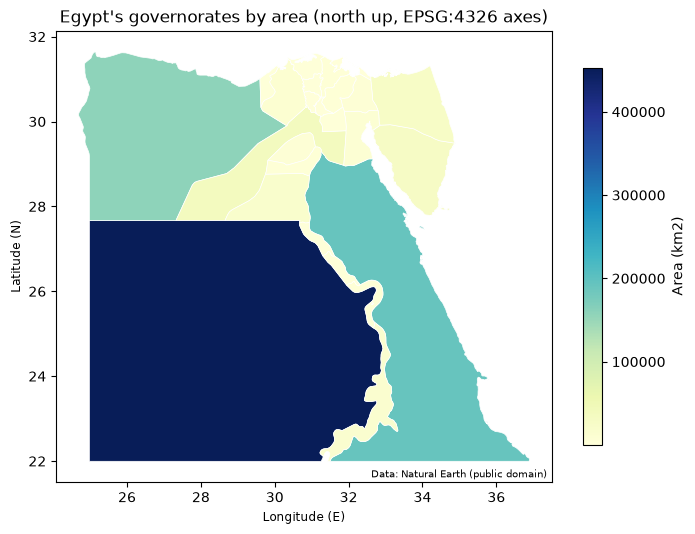

In [4]:
fig, ax = plt.subplots(figsize=(8, 7))
res.plot(column='area_km2', cmap='YlGnBu', edgecolor='white', linewidth=0.5, ax=ax,
         legend=True, legend_kwds={'label': 'Area (km2)', 'shrink': 0.7})
ax.set_aspect(1 / 0.87)
ax.set_xlabel('Longitude (E)'); ax.set_ylabel('Latitude (N)')
ax.set_title("Egypt's governorates by area (north up, EPSG:4326 axes)")
ax.text(0.99, 0.01, 'Data: Natural Earth (public domain)', transform=ax.transAxes, ha='right', fontsize=7)
plt.show()